# Bench analysis: from real files to mirror stability

**AST430, Irmak Aytekin**

The first notebook (`mirror_alignment_progress.ipynb`) tested the measuring ideas on simulated numbers.
This notebook is the **usable version**: it reads **files** (camera recordings and Calum's loop logs) and runs the same measurements on them.

| Step | Input | Output |
|---|---|---|
| 1 | dark + quiet recordings | checks: saturation, background |
| 2 | cleaned frames | fringe contrast (modulation efficiency) ± error |
| 3 | fringe **phase** in every frame | mirror position (OPD) over time, wobble RMS ± error |
| 4 | OPD over time | **which frequencies shake the mirror** |
| 5 | Calum's `loop_test.py` CSV log | loop rate, settling time, pointing stability |

The functions live in `mirror_tools.py`, so the same code can be reused for every recording.

**Right now `DEMO = True`:** the files are fake, made by `make_demo_data.py` in the same formats as real data,
with known true values, so we can check the tools give the right answers. On the bench: set `DEMO = False` and fill in the paths.

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from mirror_tools import *

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# ================= SETTINGS =================
DEMO = True                   # True = fake test files; False = real bench files

QUIET_PATH = "data/quiet_01.tif"       # real quiet recording (.tif, .fits or .npy)
DARK_PATH  = "data/dark_01.tif"        # real dark recording
LOOP_LOG_PATH = "data/loop_test.csv"   # a CSV written by Calum's loop_test.py
CALIB_PATH = None                      # a calib_matrix_*.json from loop_test.py, if you have one

WAVELENGTH_NM    = 532.0      # TO CHECK: the green laser's label
CAMERA_FPS       = 1000       # TO CHECK: the frame rate you actually recorded at
SATURATION_LEVEL = 4095       # TO CHECK: camera maximum (4095 for 12-bit, 65535 for 16-bit)
WINDOW_Y0, WINDOW_X0, WINDOW_SIZE = 16, 16, 32   # choose after looking at the first frame
# =============================================

if DEMO:
    from make_demo_data import make_all
    truth = make_all("demo_data", wavelength_nm=WAVELENGTH_NM, fps=CAMERA_FPS)
    QUIET_PATH, DARK_PATH = "demo_data/demo_quiet.tif", "demo_data/demo_dark.tif"
    LOOP_LOG_PATH = "demo_data/demo_loop_log.csv"
    print("DEMO MODE: fake files. True values used to make them:")
    for k, v in truth.items():
        print(f"   {k}: {v:.3g}" if isinstance(v, float) else f"   {k}: {v}")

DEMO MODE: fake files. True values used to make them:
   wavelength_nm: 532
   fps: 1000
   contrast: 0.8
   opd_rms_nm: 15.4
   vibration_hz: 50
   vibration_amp_nm: 8
   drift_hz: 0.7
   drift_amp_nm: 20
   background_counts: 100
   fringe_freq: 0.0854


## 1. Load and check

- **Saturation:** if the brightest stripes hit the camera's maximum, their tops get cut off and the contrast looks too low.
- **Dark level:** the camera's background with the light blocked. It must be subtracted, otherwise it adds to the mean brightness and the contrast looks too low.

quiet: 5000 frames of 64 x 64 pixels
   brightest pixel 3558 of max 4095  (87%)
   mean level 1565.7
dark: 200 frames of 64 x 64 pixels
   brightest pixel 123 of max 4095  (3%)
   mean level 99.5
average background: 99.5 counts


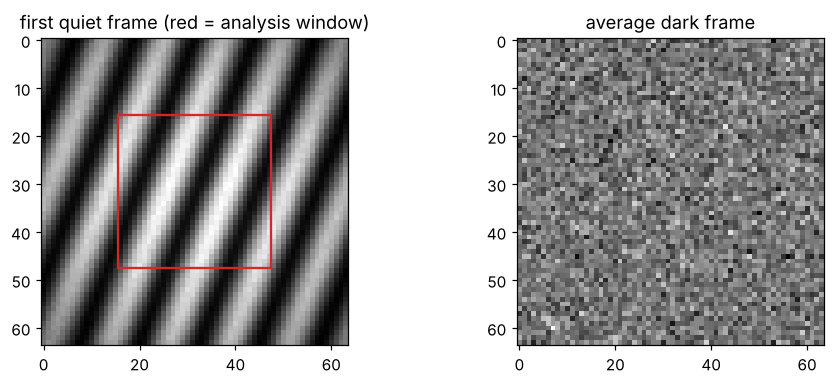

In [2]:
frames = load_frames(QUIET_PATH)
dark = load_frames(DARK_PATH)
check_frames(frames, SATURATION_LEVEL, "quiet")
check_frames(dark, SATURATION_LEVEL, "dark")
background = dark_level(dark)
print(f"average background: {background.mean():.1f} counts")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].imshow(frames[0], cmap="gray")
axes[0].add_patch(plt.Rectangle((WINDOW_X0 - 0.5, WINDOW_Y0 - 0.5), WINDOW_SIZE, WINDOW_SIZE,
                                fill=False, edgecolor="tab:red", lw=1.5))
axes[0].set_title("first quiet frame (red = analysis window)")
axes[1].imshow(background, cmap="gray"); axes[1].set_title("average dark frame")
plt.tight_layout(); plt.show()

## 2. Fringe contrast (modulation efficiency)

Subtract the dark, cut out the window, and fit stripes to **every frame**.
Each fit starts from the previous frame's answer, which is faster and keeps the stripe direction consistent.

Frames fitted: 5000 (0 failed)
Modulation efficiency: 0.79740 +- 0.00001   (frame-to-frame scatter 0.0009)
Stripe frequency     : 0.0854 stripes/pixel -> 2.7 stripes across the window


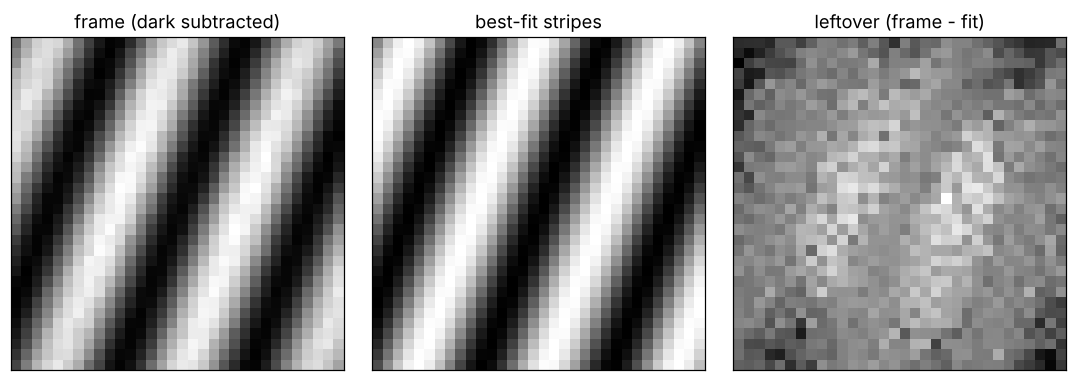

In [3]:
clean = crop(frames - background, WINDOW_Y0, WINDOW_X0, WINDOW_SIZE)
res = fit_all_frames(clean)
me = summarise(res["mod_eff"])
ff = summarise(res["fringe_freq"])
print(f"Frames fitted: {me['n']} ({res['n_failed']} failed)")
print(f"Modulation efficiency: {me['mean']:.5f} +- {me['err']:.5f}   (frame-to-frame scatter {me['scatter']:.4f})")
print(f"Stripe frequency     : {ff['mean']:.4f} stripes/pixel -> {ff['mean'] * WINDOW_SIZE:.1f} stripes across the window")
if ff["mean"] * WINDOW_SIZE < 2:
    print("   WARNING: fewer than 2 stripes in the window: the fit is unreliable")

one = fit_fringes(clean[0])
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, (title, im) in zip(axes, [("frame (dark subtracted)", clean[0]), ("best-fit stripes", one["fit"]),
                                   ("leftover (frame - fit)", clean[0] - one["fit"])]):
    ax.imshow(im, cmap="gray"); ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [4]:
# Why the dark subtraction matters: same frames, without it
no_dark = summarise(fit_all_frames(crop(frames, WINDOW_Y0, WINDOW_X0, WINDOW_SIZE), max_frames=500)["mod_eff"])
print(f"with dark subtracted   : {me['mean']:.3f}")
print(f"WITHOUT dark subtracted: {no_dark['mean']:.3f}   <- background makes the fringes look worse")

with dark subtracted   : 0.797
WITHOUT dark subtracted: 0.753   <- background makes the fringes look worse


## 3. Mirror position over time

The fit also gives the **phase**: where the stripes are, measured at the centre of the window.
When the mirror moves, the stripes slide, and one full stripe = one wavelength of OPD.
`phase_to_opd_nm` follows the phase from frame to frame, counting whole stripes (`np.unwrap`), and converts to nm.

This works if the OPD changes by **less than half a stripe between frames** (see Part 6c of the first notebook).
The mirror itself moves **half** of the OPD.

OPD wobble over 5.0 s: 15.45 +- 0.66 nm RMS   (mirror: 7.73 nm)
Typical phase error per frame: 0.23 nm of OPD


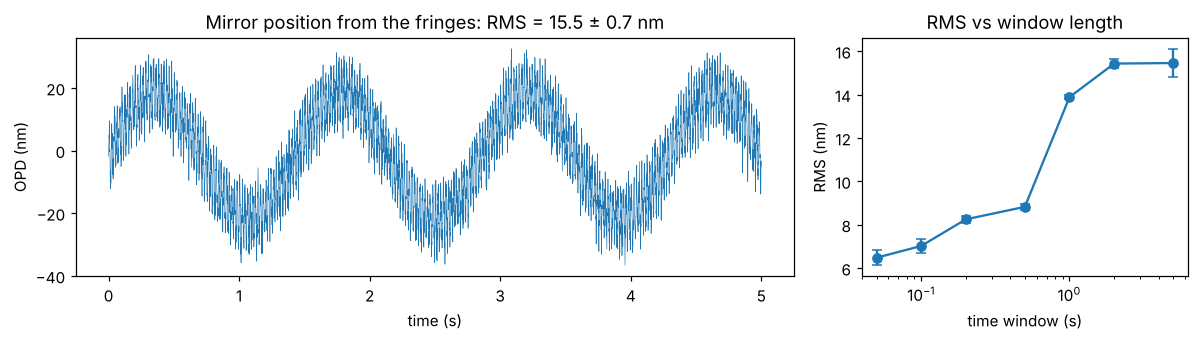

In [5]:
opd = phase_to_opd_nm(res["phase"], WAVELENGTH_NM)
t = np.arange(len(opd)) / CAMERA_FPS
duration = t[-1] + 1 / CAMERA_FPS
rms, err = rms_with_error(opd, CAMERA_FPS, window_s=duration)
print(f"OPD wobble over {duration:.1f} s: {rms:.2f} +- {err:.2f} nm RMS   (mirror: {rms/2:.2f} nm)")
print(f"Typical phase error per frame: {np.nanmedian(res['phase_err']) * WAVELENGTH_NM / (2*np.pi):.2f} nm of OPD")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].plot(t, opd - np.nanmean(opd), lw=0.4)
axes[0].set_xlabel("time (s)"); axes[0].set_ylabel("OPD (nm)")
axes[0].set_title(f"Mirror position from the fringes: RMS = {rms:.1f} ± {err:.1f} nm")
windows = np.array([0.05, 0.1, 0.2, 0.5, 1, 2, 5]); windows = windows[windows <= duration]
r = np.array([rms_with_error(opd, CAMERA_FPS, w) for w in windows])
axes[1].errorbar(windows, r[:, 0], yerr=r[:, 1], marker="o", capsize=3)
axes[1].set_xscale("log"); axes[1].set_xlabel("time window (s)"); axes[1].set_ylabel("RMS (nm)")
axes[1].set_title("RMS vs window length")
plt.tight_layout(); plt.show()

## 4. What is shaking the mirror?

The **spectrum** splits the wobble into frequencies. A sharp peak means a regular vibration
(a fan, a pump, the building at 50 or 60 Hz). This tells us **what to fix** and whether the correction loop is fast enough
(the first notebook's Part 4b: a loop should run about 15–20× faster than the vibration it fights).

Strongest vibrations:
       0.8 Hz : 17.1 nm amplitude (OPD)
      50.0 Hz : 8.1 nm amplitude (OPD)


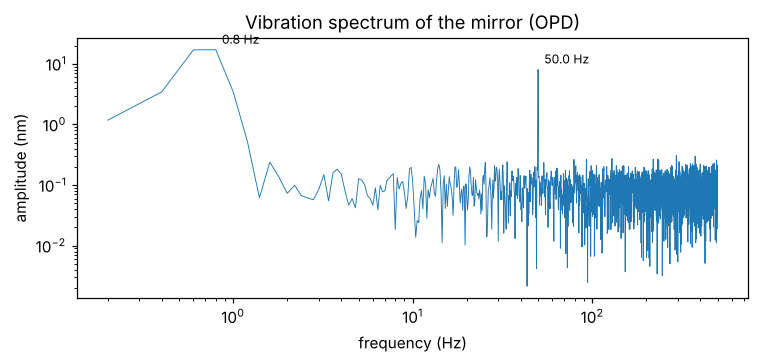

In [6]:
freqs, amp = amplitude_spectrum(opd, CAMERA_FPS)
peaks = top_peaks(freqs, amp, n=3, fmin=0.3)
peaks = [(f, a) for f, a in peaks if a > 5 * np.median(amp)]   # keep only real peaks, not the noise floor
print("Strongest vibrations:")
for f, a in peaks:
    print(f"   {f:7.1f} Hz : {a:.1f} nm amplitude (OPD)")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.loglog(freqs[1:], amp[1:], lw=0.6)
for f, a in peaks:
    ax.annotate(f"{f:.1f} Hz", (f, a), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("amplitude (nm)")
ax.set_title("Vibration spectrum of the mirror (OPD)")
plt.tight_layout(); plt.show()

## 5. Calum's loop: rate, settling, stability

`loop_test.py` already runs a real camera → computer → piezo loop and logs every cycle.
These tools read its CSV log:
- **loop rate:** how often it corrects (sets which vibrations it can fight),
- **settling time:** how long until the target stays within 2 px,
- **pointing stability:** RMS of the position after settling, with the same block error bar as above.

Run: 29.7 s, 750 cycles, 2.7% lost detections
Loop rate: 25.3 Hz  (cycle time scatter 4.1 ms)
Settled within 2 px after 0.36 s
Stability after settling, cx: 0.44 +- 0.01 px RMS
Stability after settling, cy: 0.40 +- 0.01 px RMS
Final voltages: x = 78.0 V, y = 72.9 V


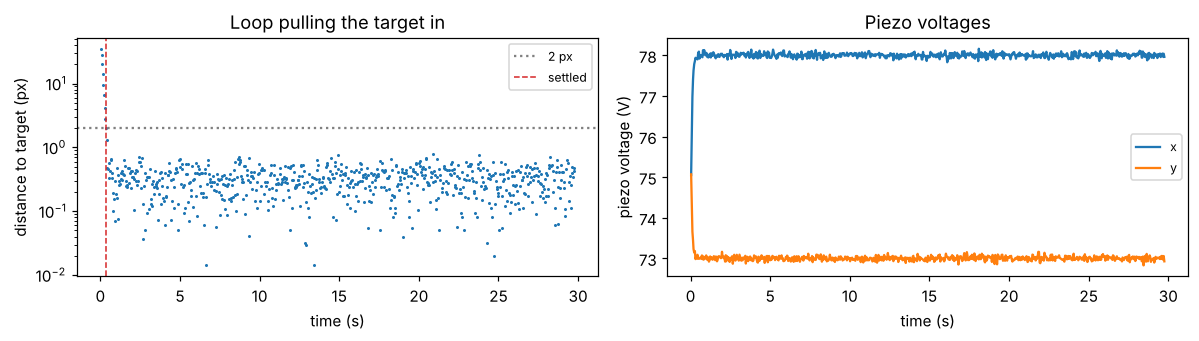

In [7]:
log = load_loop_log(LOOP_LOG_PATH)
s = loop_summary(log, settle_px=2.0)
print(f"Run: {s['duration_s']:.1f} s, {s['n_frames']} cycles, {s['lost_fraction']:.1%} lost detections")
print(f"Loop rate: {s['loop_rate_hz']:.1f} Hz  (cycle time scatter {s['dt_scatter_ms']:.1f} ms)")
print(f"Settled within 2 px after {s['settle_time_s']:.2f} s")
for axis in ("cx_px", "cy_px"):
    if axis + "_rms" in s:
        print(f"Stability after settling, {axis[:2]}: {s[axis + '_rms']:.2f} +- {s[axis + '_rms_err']:.2f} px RMS")
print(f"Final voltages: x = {s['final_vx']:.1f} V, y = {s['final_vy']:.1f} V")

lt = log["t_s"]; dist = np.hypot(log["ex_px"], log["ey_px"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].semilogy(lt, dist, ".", ms=2)
axes[0].axhline(2, color="gray", ls=":", label="2 px")
axes[0].axvline(s["settle_time_s"], color="tab:red", ls="--", lw=1, label="settled")
axes[0].set_xlabel("time (s)"); axes[0].set_ylabel("distance to target (px)")
axes[0].set_title("Loop pulling the target in"); axes[0].legend(fontsize=8)
axes[1].plot(lt, log["vx"], label="x"); axes[1].plot(lt, log["vy"], label="y")
axes[1].set_xlabel("time (s)"); axes[1].set_ylabel("piezo voltage (V)")
axes[1].set_title("Piezo voltages"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [8]:
# What is still moving the target after the loop has settled? (spectrum of the leftover position)
after = slice(s["settled_index"], None)
tu, cxu = resample_uniform(lt[after], log["cx_px"][after], s["loop_rate_hz"])   # even time steps
f_loop, a_loop = amplitude_spectrum(cxu, s["loop_rate_hz"])
for f, a in top_peaks(f_loop, a_loop, n=2, fmin=0.2):
    print(f"   {f:5.2f} Hz : {a:.2f} px")
print(f"The loop can only see vibrations below {s['loop_rate_hz']/2:.1f} Hz (half its rate), "
      f"and fights them well only below roughly {s['loop_rate_hz']/20:.1f} Hz.")

if CALIB_PATH:
    J = load_calibration(CALIB_PATH)
    print("Calibration (pixels per volt):\n", J)

    2.99 Hz : 0.27 px
    6.90 Hz : 0.06 px
The loop can only see vibrations below 12.6 Hz (half its rate), and fights them well only below roughly 1.3 Hz.


## What is still needed for real data

1. **Three numbers from the bench:** the laser wavelength, the real frame rate, and the camera maximum (12- or 16-bit).
2. **The file format** the Tucsen software saves (`.tif`, `.fits` and `.npy` already work).
3. **A window with 2–3 stripes near the beam centre.** The fit assumes even brightness; a real beam fades towards its edges.
   In the demo (beam ~40 px wide) a 32 px window still gives 0.797 for a true 0.80.
4. **Calum's logs:** one run with the loop on is enough to fill section 5 with real numbers.
5. **Later:** the pixel scale (ruler or piezo method) to turn pixels into tilt, and the timestamps, to catch dropped frames.